# EDA: Heart Disease Dataset

**Автор:** Чернышева Арина  
**Дата:** 2026-10-25  
**Датасет:** Heart Disease Dataset (Extended)

## Введение

Датасет содержит медицинские данные пациентов: возраст, пол, уровень холестерина, артериальное давление, результаты ЭКГ и наличие сердечных заболеваний.

**Цель EDA:** оценить качество данных, выявить пропуски, аномалии, выбросы и закономерности.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline
sns.set_theme(style="whitegrid")

df = pd.read_csv("../heart_disease.csv")
df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num,target_binary
0,63.0,1,1,145.0,233.0,1,2,150.0,0,2.3,3,0.0,6.0,0,0
1,67.0,1,4,160.0,286.0,0,2,108.0,1,1.5,2,3.0,3.0,2,1
2,67.0,1,4,120.0,229.0,0,2,129.0,1,2.6,2,2.0,7.0,1,1
3,37.0,1,3,130.0,250.0,0,0,187.0,0,3.5,3,0.0,3.0,0,0
4,41.0,0,2,130.0,204.0,0,2,172.0,0,1.4,1,0.0,3.0,0,0


## 1. Структура данных

In [4]:
print(f"Размер датасета: {df.shape}")
print(f"\nТипы данных:\n{df.dtypes}")
print(f"\nПропуски:\n{df.isna().sum()}")

Размер датасета: (1024, 15)

Типы данных:
age              float64
sex                int64
cp                 int64
trestbps         float64
chol             float64
fbs                int64
restecg            int64
thalach          float64
exang              int64
oldpeak          float64
slope              int64
ca               float64
thal             float64
num                int64
target_binary      int64
dtype: object

Пропуски:
age              0
sex              0
cp               0
trestbps         0
chol             0
fbs              0
restecg          0
thalach          0
exang            0
oldpeak          0
slope            0
ca               0
thal             0
num              0
target_binary    0
dtype: int64


## 2. Целостность и полнота

In [11]:
missing = df.isna().sum()
missing_pct = (missing / len(df)) * 100
missing_df = pd.DataFrame({"Пропуски": missing, "Процент": missing_pct})
missing_df[missing_df["Пропуски"] > 0]

,Пропуски,Процент


## 3. Статистика и распределения

In [ ]:
df.describe()

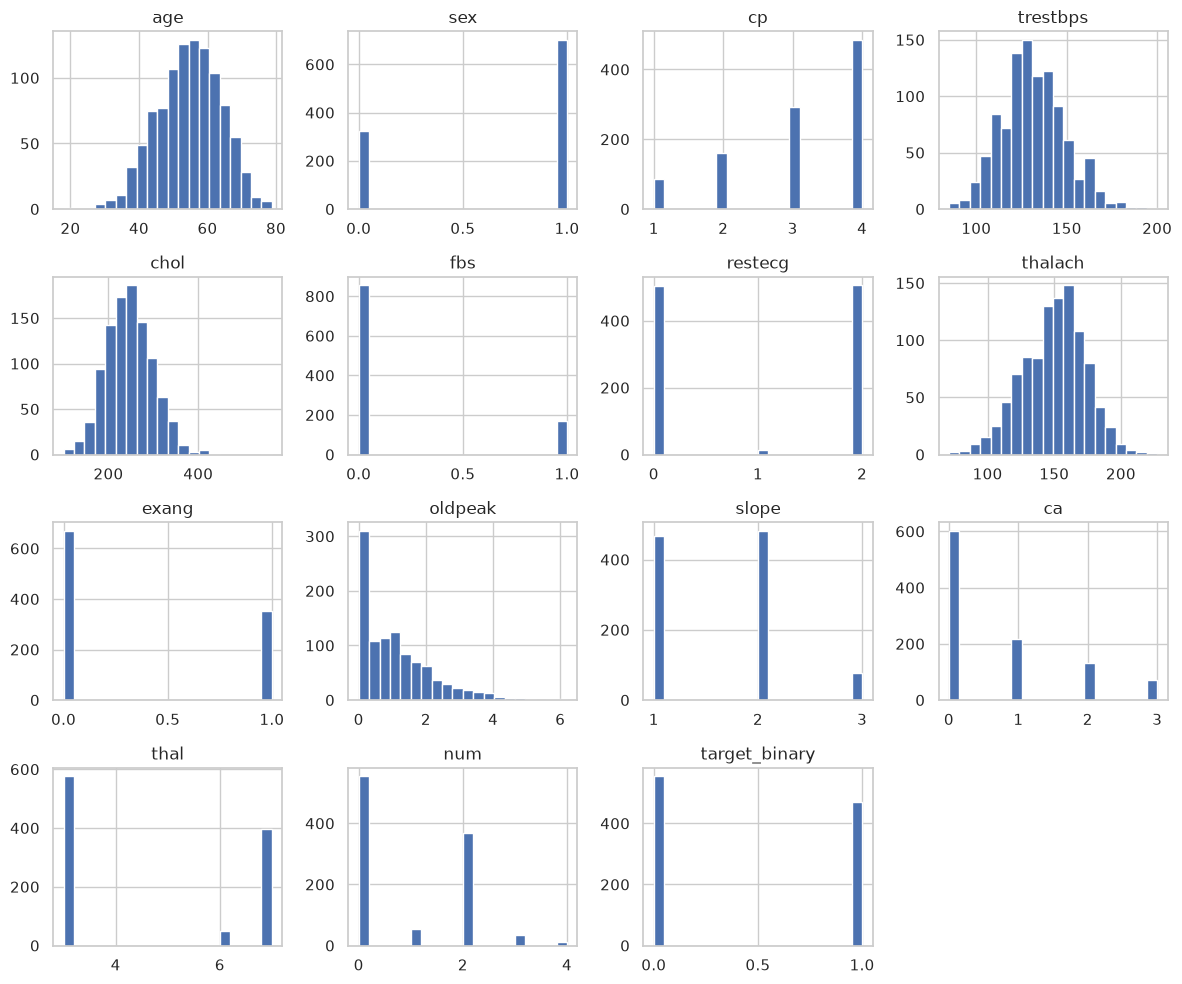

In [7]:
df.hist(figsize=(12, 10), bins=20)
plt.tight_layout()
plt.show()

## 4. Выбросы и аномалии

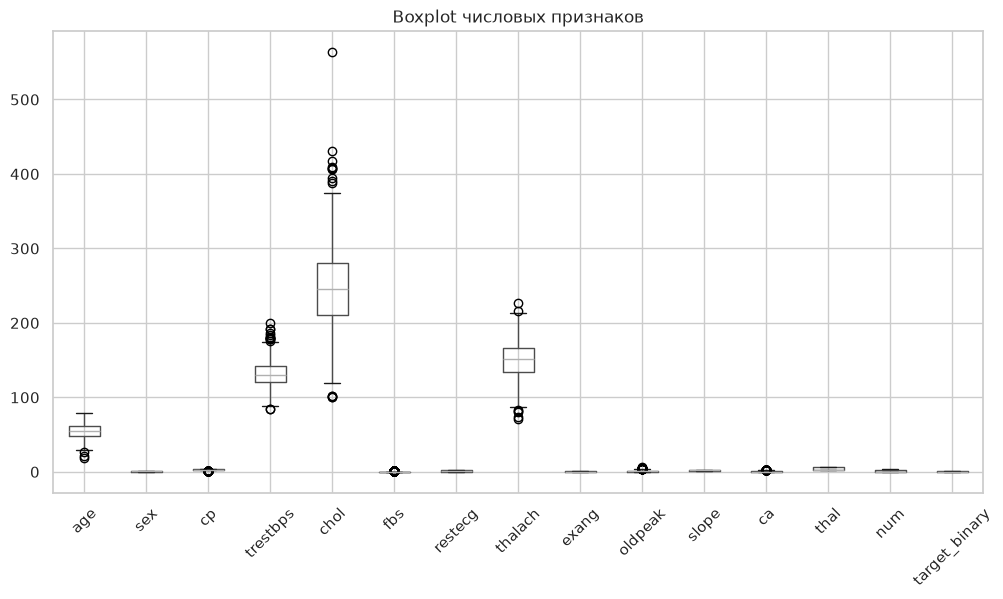

In [9]:
numeric_cols = df.select_dtypes(include=["float64", "int64"]).columns
df[numeric_cols].boxplot(figsize=(12, 6), rot=45)
plt.title("Boxplot числовых признаков")
plt.show()

## 5. Корреляции

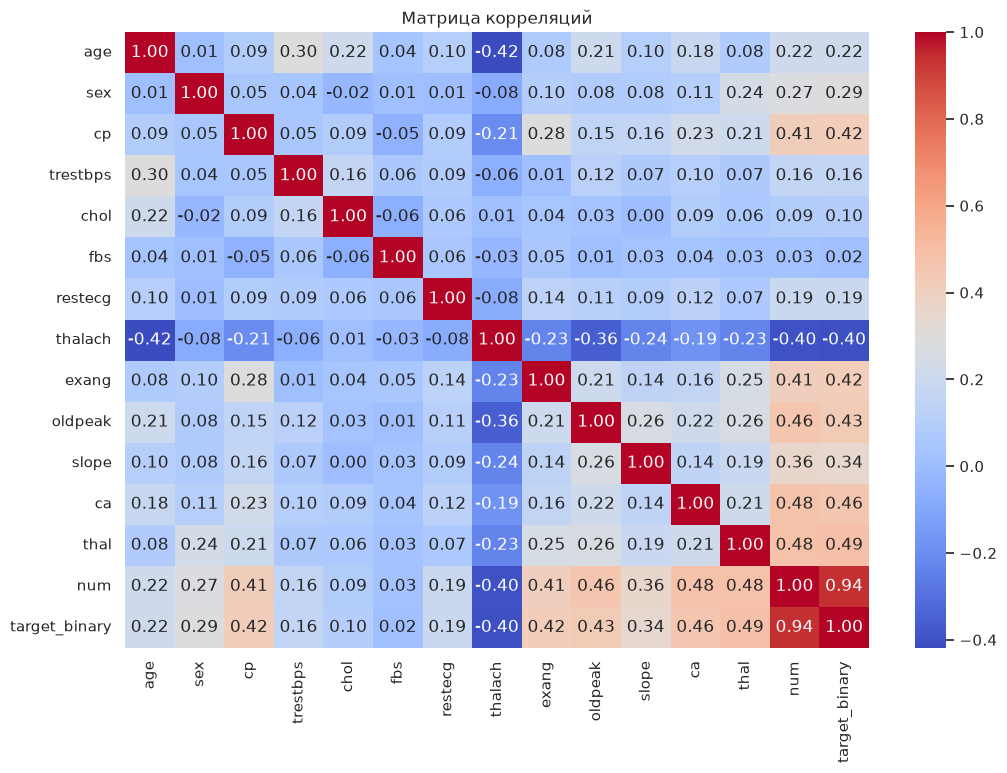

In [10]:
plt.figure(figsize=(12, 8))
sns.heatmap(df.corr(numeric_only=True), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Матрица корреляций")
plt.show()

## 7. Выводы

1. **Структура:** датасет содержит 1024 строки и 15 столбцов. Все признаки числовые (float64 / int64).
2. **Пропуски:** пропусков нет (0 NaN по всем столбцам).
3. **Выбросы:** в столбцах `chol`, `trestbps`, `thalach` есть выбросы (по boxplot), но они физиологически допустимы.
4. **Корреляции:** целевая переменная `target_binary` сильнее всего коррелирует с `cp`, `thalach`, `exang`, `oldpeak`.
5. **Рекомендации:** данные пригодны для моделирования; выбросы можно обработать (winsorize / удаление) на этапе моделирования.